# Who Moved in the Bottom Quartile, and Did Delivery Matter?

Two questions raised by Part 3's income gradient (Democrats losing ground in the poorest quartile of counties in every cycle since 2012):

**A. Who moved?** The bottom-quartile shift is a county aggregate. Q1 counties are two populations — rural white counties and Hispanic/Black counties — that Part 2 already showed moved in different years. Split the Q1 shift by composition, then go to the individual level: is it low-income *people* who left the Biden coalition, or other residents of low-income *counties*?

**B. Did delivery matter?** Parts 3–5 tested whether local economic *outcomes* (wages, jobs) registered. They did not. This section tests the more direct version of the attribution claim: did counties that received the most visible Biden-era federal money — IIJA infrastructure and ARPA recovery funds — shift less, or perceive the economy differently, or defect less?

**Inputs:** `outputs/tables/county_multiyear_swing.csv`, `data/processed/county_economic_profile.csv`, `county_covariates.csv`, `ces_2024_attribution.csv`, `data/raw/ces/ces_2024.csv`, `data/raw/ces_panel/ces_panel_wide.csv`, `data/raw/usaspending/county_delivery.csv` (from `usaspending_pull.py`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

RAW_DIR     = Path('../data/raw')
PROC_DIR    = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures')
TABLES_DIR  = Path('../outputs/tables')

def wmean(x, w):
    m = x.notna() & w.notna()
    return np.average(x[m], weights=w[m]) if m.any() else np.nan

# County panel: multi-year swing vs Obama 2012 + composition + turnout by year
sw = pd.read_csv(TABLES_DIR / 'county_multiyear_swing.csv')
prof = pd.read_csv(PROC_DIR / 'county_economic_profile.csv')
ret = pd.read_csv(RAW_DIR / 'mit_election_lab' / 'county_returns.csv')
cty = sw.merge(prof[['county_fips', 'white_nh_share', 'white_nocollege', 'college_share', 'population']], on='county_fips')
for yr in [2012, 2016, 2020, 2024]:
    cty = cty.merge(ret.loc[ret['year'] == yr, ['county_fips', 'total_votes']].rename(columns={'total_votes': f'total_{yr}'}), on='county_fips')
cty['income_q'] = pd.qcut(cty['med_income'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
cty['nonwhite'] = 1 - cty['white_nh_share']
print(f'Counties: {len(cty):,}')
print('Share of 2024 votes by county income quartile:',
      {q: f'{100 * g["total_2024"].sum() / cty["total_2024"].sum():.1f}%' for q, g in cty.groupby('income_q')})

Counties: 3,110
Share of 2024 votes by county income quartile: {'Q1': '5.5%', 'Q2': '12.7%', 'Q3': '21.2%', 'Q4': '60.6%'}


## A1. The bottom quartile, split by composition

Turnout-weighted change in Democratic share relative to Obama 2012, by cycle. Q1 = poorest quartile of counties by ACS 2020 median household income.

In [2]:
q1 = cty[cty['income_q'] == 'Q1'].copy()
q1['race_t'] = pd.qcut(q1['nonwhite'], 3, labels=['mostly white', 'mixed', 'heavily nonwhite'])
cty['race_t'] = pd.qcut(cty['nonwhite'], 3, labels=['mostly white', 'mixed', 'heavily nonwhite'])

def by_group(df, col, label):
    rows = []
    for g, s in df.groupby(col):
        rows.append({label: g, 'counties': len(s), 'share_of_votes': s['total_2024'].sum() / df['total_2024'].sum(),
                     'nonwhite_mean': s['nonwhite'].mean(), 'white_nocollege_mean': s['white_nocollege'].mean(),
                     'vs2012_2016': wmean(s['swing_2016'], s['total_2016']), 'vs2012_2020': wmean(s['swing_2020'], s['total_2020']),
                     'vs2012_2024': wmean(s['swing_2024'], s['total_2024']),
                     'change_2020_2024': wmean(s['swing_2024'] - s['swing_2020'], s['total_2024'])})
    return pd.DataFrame(rows).set_index(label)

q1_race = by_group(q1, 'race_t', 'Q1 counties by nonwhite share')
all_race = by_group(cty, 'race_t', 'All counties by nonwhite share')
print(f'Q1 counties: {len(q1)} ({100 * q1["total_2024"].sum() / cty["total_2024"].sum():.1f}% of 2024 votes)\n')
print(q1_race.round(3).to_string())
print()
print(all_race.round(3).to_string())

Q1 counties: 778 (5.5% of 2024 votes)

                               counties  share_of_votes  nonwhite_mean  white_nocollege_mean  vs2012_2016  vs2012_2020  vs2012_2024  change_2020_2024
Q1 counties by nonwhite share                                                                                                                        
mostly white                        260           0.269          0.063                 0.793       -9.603       -9.101      -10.686            -1.576
mixed                               259           0.311          0.286                 0.595       -6.280       -6.227       -8.369            -2.113
heavily nonwhite                    259           0.420          0.607                 0.329       -3.230       -4.589       -8.865            -4.264

                                counties  share_of_votes  nonwhite_mean  white_nocollege_mean  vs2012_2016  vs2012_2020  vs2012_2024  change_2020_2024
All counties by nonwhite share                             

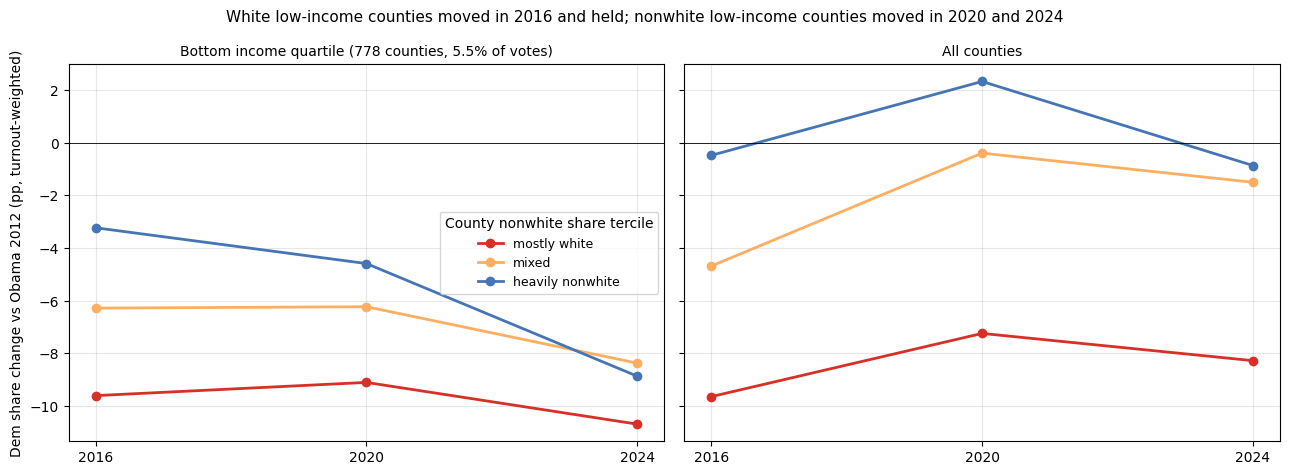

Largest Q1 counties by 2024 votes:
      state  county_fips  med_income  nonwhite  white_nocollege  total_2024  swing_2016  swing_2020  swing_2024
   NEW YORK      36005.0       41895      0.91             0.07      362890       -1.70       -8.03      -18.11
      TEXAS      48215.0       41846      0.94             0.05      217265       -1.90      -12.36      -22.29
  LOUISIANA      22071.0       43258      0.69             0.19      159130        0.51        2.85        1.87
      TEXAS      48061.0       41200      0.91             0.07      116153       -0.48       -8.88      -18.28
  LOUISIANA      22017.0       42003      0.56             0.33       94699       -1.38        0.60       -0.33
MISSISSIPPI      28049.0       45380      0.76             0.17       86830       -0.08        2.08        0.90
 NEW MEXICO      35013.0       44024      0.73             0.19       85407       -2.20        2.12       -2.13
    GEORGIA      13245.0       43882      0.66             0.26      

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, tab, title in [(axes[0], q1_race, 'Bottom income quartile (778 counties, 5.5% of votes)'),
                       (axes[1], all_race, 'All counties')]:
    for g, color in [('mostly white', '#d73027'), ('mixed', '#fdae61'), ('heavily nonwhite', '#4575b4')]:
        ax.plot([2016, 2020, 2024], tab.loc[g, ['vs2012_2016', 'vs2012_2020', 'vs2012_2024']], marker='o', lw=2, color=color, label=g)
    ax.axhline(0, color='black', lw=0.6); ax.set_xticks([2016, 2020, 2024]); ax.set_title(title, fontsize=10); ax.grid(alpha=0.3)
axes[0].set_ylabel('Dem share change vs Obama 2012 (pp, turnout-weighted)')
axes[0].legend(title='County nonwhite share tercile', fontsize=9)
plt.suptitle('White low-income counties moved in 2016 and held; nonwhite low-income counties moved in 2020 and 2024', fontsize=11)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'q1_by_composition.png', dpi=150, bbox_inches='tight')
plt.show()

print('Largest Q1 counties by 2024 votes:')
print(q1.nlargest(8, 'total_2024')[['state', 'county_fips', 'med_income', 'nonwhite', 'white_nocollege', 'total_2024', 'swing_2016', 'swing_2020', 'swing_2024']].round(2).to_string(index=False))

## A2. Individual income versus county income

CES 2024, recalled Biden 2020 voters with a 2024 major-party vote. `faminc`: family income in 16 bands (1 = under $10k … 16 = $500k+; 97 = declined).

In [4]:
raw24 = pd.read_csv(RAW_DIR / 'ces' / 'ces_2024.csv', low_memory=False, usecols=['caseid', 'faminc', 'race', 'hispanic'])
d = pd.read_csv(PROC_DIR / 'ces_2024_attribution.csv').merge(raw24, on='caseid')
d['inc_grp'] = pd.cut(d['faminc'].where(d['faminc'] <= 16), [0, 3, 5, 9, 12, 16], labels=['<$30k', '$30-50k', '$50-100k', '$100-200k', '$200k+'])
d['racecat'] = np.select([d['hispanic'] == 1, d['race'] == 1, d['race'] == 2], ['Hispanic', 'White', 'Black'], 'Other')
cov = pd.read_csv(PROC_DIR / 'county_covariates.csv')
cov['cty_income_q'] = pd.qcut(cov['med_income'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
d = d.merge(cov[['county_fips', 'cty_income_q']], on='county_fips', how='left')

sw24 = d[(d['presvote_prior_party'] == 'D') & d['voted_2024'] & d['weight_post'].notna()].copy()
sw24['switch'] = sw24['vote_R_2024']
print(f'Recalled-Biden voters with a 2024 major-party vote: {len(sw24):,}\n')

def rate_table(df, col, label):
    rows = []
    for g, s in df.groupby(col):
        rows.append({label: g, 'N': len(s), 'switch_wtd': wmean(s['switch'], s['weight_post']),
                     'switch_unwtd': s['switch'].mean(), 'perceived_econ_wtd': wmean(s['perceived_econ'], s['weight'])})
    return pd.DataFrame(rows).set_index(label)

ind_inc = rate_table(sw24, 'inc_grp', 'individual family income')
cty_inc = rate_table(sw24, 'cty_income_q', 'county income quartile')
race_tab = rate_table(sw24, 'racecat', 'race/ethnicity')
print('Switch to Trump by INDIVIDUAL family income:'); print(ind_inc.round(3).to_string()); print()
print('Switch to Trump by COUNTY income quartile:'); print(cty_inc.round(3).to_string()); print()
print('Switch to Trump by race/ethnicity:'); print(race_tab.round(3).to_string())

Recalled-Biden voters with a 2024 major-party vote: 20,608

Switch to Trump by INDIVIDUAL family income:
                             N  switch_wtd  switch_unwtd  perceived_econ_wtd
individual family income                                                    
<$30k                     3656       0.071         0.033               0.127
$30-50k                   3266       0.060         0.031               0.304
$50-100k                  6340       0.063         0.029               0.446
$100-200k                 4564       0.063         0.028               0.725
$200k+                    1377       0.064         0.030               0.859

Switch to Trump by COUNTY income quartile:
                            N  switch_wtd  switch_unwtd  perceived_econ_wtd
county income quartile                                                     
Q1                        926       0.072         0.030               0.250
Q2                       2685       0.057         0.026               0.417
Q3      

In [5]:
# Cross-level: low-income individuals inside low-income counties
sw24['lowinc'] = sw24['faminc'].where(sw24['faminc'] <= 16) <= 5
print('Individual under/over $50k, within county Q1 and Q4 (weighted switch rate):')
for cq in ['Q1', 'Q4']:
    for li, lab in [(True, 'under $50k'), (False, '$50k+')]:
        s = sw24[(sw24['cty_income_q'] == cq) & (sw24['lowinc'] == li)]
        print(f'  county {cq}, individual {lab:10s} N={len(s):>5,}  {wmean(s["switch"], s["weight_post"]):.1%}')
print()
print('Race x income (weighted switch rate):')
race_inc = sw24.groupby(['racecat', 'inc_grp']).apply(lambda g: pd.Series({'N': len(g), 'switch': wmean(g['switch'], g['weight_post'])})).unstack()
print(race_inc['switch'].round(3).to_string()); print(); print(race_inc['N'].astype(int).to_string())

# Logit: does individual income predict switching net of race and party? Does race survive income and county income?
sw24['inc_num'] = sw24['faminc'].where(sw24['faminc'] <= 16)
sw24['hisp'] = (sw24['racecat'] == 'Hispanic').astype(int); sw24['black'] = (sw24['racecat'] == 'Black').astype(int)
sw24['cty_q1'] = (sw24['cty_income_q'] == 'Q1').astype(int)
m = sw24.dropna(subset=['inc_num', 'pid7c', 'age']).copy()
wm_ = m['weight_post'] * len(m) / m['weight_post'].sum()
def wlogit(f, data, w):
    return smf.glm(f, data=data, family=sm.families.Binomial(), freq_weights=w).fit(cov_type='cluster', cov_kwds={'groups': data['county_fips']})
l1 = wlogit('switch ~ inc_num', m, wm_)
l2 = wlogit('switch ~ inc_num + hisp + black + pid7c + college + age', m, wm_)
l3 = wlogit('switch ~ inc_num + hisp + black + pid7c + college + age + cty_q1 + log_income', m, wm_)
print()
print('Logit, P(switch) among recalled Biden voters (county-clustered):')
print(f'{"term":10s} {"income only":>14s} {"+race,party,demog":>20s} {"+county income":>16s}')
for v in ['inc_num', 'hisp', 'black', 'cty_q1', 'log_income']:
    print(f'{v:10s} ' + ' '.join(f'{mm.params[v]:+7.3f} ({mm.bse[v]:.3f})' if v in mm.params else ' ' * 15 for mm in [l1, l2, l3]))

Individual under/over $50k, within county Q1 and Q4 (weighted switch rate):
  county Q1, individual under $50k N=  512  5.3%
  county Q1, individual $50k+      N=  414  9.9%
  county Q4, individual under $50k N=3,453  6.4%
  county Q4, individual $50k+      N=9,001  6.4%

Race x income (weighted switch rate):
inc_grp   <$30k  $30-50k  $50-100k  $100-200k  $200k+
racecat                                              
Black     0.048    0.042     0.062      0.037   0.051
Hispanic  0.136    0.066     0.108      0.114   0.069
Other     0.095    0.064     0.068      0.060   0.045
White     0.057    0.064     0.050      0.060   0.069

inc_grp   <$30k  $30-50k  $50-100k  $100-200k  $200k+
racecat                                              
Black       837      559       874        422      87
Hispanic    368      342       604        377     103
Other       220      171       366        309     146
White      2231     2194      4496       3456    1041

Logit, P(switch) among recalled Biden v

In [6]:
# Panel: 2020 income and race, Biden 2020 -> 2024 (contemporaneous). Cross-tab only - 39 events.
wp = pd.read_csv(RAW_DIR / 'ces_panel' / 'ces_panel_wide.csv', low_memory=False)
inc20 = pd.read_csv(RAW_DIR / 'ces_panel' / 'merged_recontact_2024_vv.csv', usecols=['caseid_20', 'faminc_new_20'], low_memory=False).rename(columns={'caseid_20': 'panel_id', 'faminc_new_20': 'faminc_20'})
wp = wp.merge(inc20, on='panel_id')
bp = wp[(wp['presvote_post_party_2020'] == 'D') & wp['presvote_post_party_2024'].isin(['D', 'R'])].copy()
bp['switch'] = (bp['presvote_post_party_2024'] == 'R').astype(int)
bp['inc_grp'] = pd.cut(bp['faminc_20'].where(bp['faminc_20'] <= 16), [0, 3, 5, 9, 12, 16], labels=['<$30k', '$30-50k', '$50-100k', '$100-200k', '$200k+'])
bp['racecat'] = np.select([bp['hispanic'] == 1, bp['race'] == 1, bp['race'] == 2], ['Hispanic', 'White', 'Black'], 'Other')
print('Panel, Biden 2020 -> 2024, by 2020 family income (unweighted; events in parentheses):')
for g, s in bp.groupby('inc_grp'): print(f'  {g:10s} N={len(s):>5}  {s["switch"].mean():.1%} ({int(s["switch"].sum())})')
print('by race/ethnicity:')
for g, s in bp.groupby('racecat'): print(f'  {g:9s} N={len(s):>5}  {s["switch"].mean():.1%} ({int(s["switch"].sum())})')
print('\nThe panel has 38 Hispanic Biden voters and 3-11 events per income cell; it cannot confirm or contradict A2.')

Panel, Biden 2020 -> 2024, by 2020 family income (unweighted; events in parentheses):
  <$30k      N=  332  3.3% (11)
  $30-50k    N=  289  2.8% (8)
  $50-100k   N=  539  1.7% (9)
  $100-200k  N=  316  1.6% (5)
  $200k+     N=   61  4.9% (3)
by race/ethnicity:
  Black     N=  311  2.9% (9)
  Hispanic  N=   38  0.0% (0)
  Other     N=  269  2.2% (6)
  White     N= 1066  2.3% (24)

The panel has 38 Hispanic Biden voters and 3-11 events per income cell; it cannot confirm or contradict A2.


## B. Did delivery matter?

County obligations under IIJA (infrastructure) and ARPA (recovery funds) from USAspending, by place of performance, March/November 2021 through Election Day 2024. Per capita, log-transformed, top 1% winsorized (federal labs, state-capital pass-throughs, counties with 64 residents).

Three tests, each repeating an earlier null with delivery added: county swing (Part 3), individual perception (Part 4), and individual switching (Part 4). If money that visibly arrived in a county did not register, that is the attribution failure measured at the point of delivery.

In [7]:
dl = pd.read_csv(RAW_DIR / 'usaspending' / 'county_delivery.csv')
for k in ['iija', 'arpa']:
    pc = dl[f'{k}_pop_pc'].replace([np.inf, -np.inf], np.nan)
    cap = pc.quantile(0.99)
    dl[f'{k}_pc_w'] = pc.clip(upper=cap)
    dl[f'log_{k}_pc'] = np.log1p(dl[f'{k}_pc_w'])
    print(f'{k}: per-capita median ${pc.median():,.0f}, winsorized at p99 = ${cap:,.0f}')

cc = cov.merge(dl[['county_fips', 'iija_pop', 'arpa_pop', 'iija_pc_w', 'arpa_pc_w', 'log_iija_pc', 'log_arpa_pc']], on='county_fips', how='left')
cc = cc.merge(pd.read_csv(RAW_DIR / 'news_deserts' / 'lni_county_summary.csv')[['county_fips', 'rucc']], on='county_fips', how='left')
cc = cc.dropna(subset=['log_iija_pc', 'log_arpa_pc', 'rucc']).copy()
cc['log_pop'] = np.log(cc['population'])
for v in ['log_iija_pc', 'log_arpa_pc']:
    cc[v + '_z'] = (cc[v] - cc[v].mean()) / cc[v].std()
print(f'\nCounties with delivery data: {len(cc):,}')
print(f'corr(log ARPA per capita, log population) = {cc[["log_arpa_pc", "log_pop"]].corr().iloc[0, 1]:.2f};  with 2020 Dem share = {cc[["log_arpa_pc", "dem_share_2020"]].corr().iloc[0, 1]:.2f}')
print(f'corr(log IIJA per capita, log population) = {cc[["log_iija_pc", "log_pop"]].corr().iloc[0, 1]:.2f};  with 2020 Dem share = {cc[["log_iija_pc", "dem_share_2020"]].corr().iloc[0, 1]:.2f}')
comp = 'log_income + college_share + white_nocollege + dem_share_2020'
urban = 'C(rucc) + log_pop'

# Where did the money go? By county income quartile and by 2020 partisanship (population-weighted per capita)
cc['dem_t'] = pd.qcut(cc['dem_share_2020'], 3, labels=['Rep counties', 'mixed', 'Dem counties'])
print('\nPer-capita obligations (population-weighted mean, winsorized):')
print(f'{"":16s} {"IIJA $/cap":>11s} {"ARPA $/cap":>11s}')
for col, lab in [('cty_income_q', 'county income'), ('dem_t', '2020 partisanship')]:
    for g, s in cc.groupby(col):
        print(f'{str(g):16s} {wmean(s["iija_pc_w"], s["population"]):>11,.0f} {wmean(s["arpa_pc_w"], s["population"]):>11,.0f}')

iija: per-capita median $671, winsorized at p99 = $17,503
arpa: per-capita median $421, winsorized at p99 = $18,131

Counties with delivery data: 3,101
corr(log ARPA per capita, log population) = 0.23;  with 2020 Dem share = 0.39
corr(log IIJA per capita, log population) = -0.16;  with 2020 Dem share = -0.04

Per-capita obligations (population-weighted mean, winsorized):
                  IIJA $/cap  ARPA $/cap
Q1                     1,004         922
Q2                       887       1,155
Q3                     1,027       1,424
Q4                       776       1,778
Rep counties           1,023         503
mixed                    787         653
Dem counties             861       1,843


In [8]:
# (i) County swing 2020->2024: notebook 05 M2 specification + delivery (WLS, 2020 turnout weights, HC3)
base = ('swing_2024 ~ log_income + college_share + white_nocollege + unemp_rate + dem_share_2020'
        ' + mfg_share_2016 + private_emp_pct_chg_2020_2024 + real_pay_pct_chg_2020_2024')
reg = cc.merge(ret.loc[ret['year'] == 2020, ['county_fips', 'total_votes']].rename(columns={'total_votes': 'w2020'}), on='county_fips')
reg = reg.dropna(subset=['mfg_share_2016', 'private_emp_pct_chg_2020_2024', 'real_pay_pct_chg_2020_2024']).copy()
m0 = smf.wls(base, data=reg, weights=reg['w2020']).fit(cov_type='HC3')
m1 = smf.wls(base + ' + log_iija_pc_z + log_arpa_pc_z', data=reg, weights=reg['w2020']).fit(cov_type='HC3')
m1u = smf.wls(base + f' + log_iija_pc_z + log_arpa_pc_z + {urban}', data=reg, weights=reg['w2020']).fit(cov_type='HC3')
reg_r = reg[(reg['iija_pc_w'] < reg['iija_pc_w'].quantile(0.95)) & (reg['arpa_pc_w'] < reg['arpa_pc_w'].quantile(0.95))]
m1r = smf.wls(base + f' + log_iija_pc_z + log_arpa_pc_z + {urban}', data=reg_r, weights=reg_r['w2020']).fit(cov_type='HC3')
print(f'(i) County margin swing 2020->2024, N = {len(reg):,}   R2 without delivery {m0.rsquared:.3f}, with {m1.rsquared:.3f}')
print(f'    {"specification":40s} {"IIJA pp/SD":>14s} {"ARPA pp/SD":>14s}')
for lab, mm in [('Part 3 controls', m1), ('+ RUCC + log population', m1u), (f'+ RUCC + log pop, top 5% dropped (N={len(reg_r):,})', m1r)]:
    print(f'    {lab:40s} {mm.params["log_iija_pc_z"]:+6.3f} ({mm.bse["log_iija_pc_z"]:.3f}) {mm.params["log_arpa_pc_z"]:+6.3f} ({mm.bse["log_arpa_pc_z"]:.3f})')

(i) County margin swing 2020->2024, N = 2,913   R2 without delivery 0.434, with 0.451
    specification                                IIJA pp/SD     ARPA pp/SD
    Part 3 controls                          +0.548 (0.238) +0.382 (0.172)
    + RUCC + log population                  +0.501 (0.227) +0.433 (0.170)
    + RUCC + log pop, top 5% dropped (N=2,653) +0.546 (0.292) +0.778 (0.301)


In [9]:
# (ii) Individual perception: notebook 06 stage 1 + delivery (WLS, commonweight, county-clustered)
dd = d.merge(cc[['county_fips', 'log_iija_pc_z', 'log_arpa_pc_z', 'rucc', 'log_pop']], on='county_fips', how='inner')
dd = dd.dropna(subset=['perceived_econ', 'pid7c']).copy()
actual = 'real_pay_pct_chg_2020_2024_z + private_emp_pct_chg_2020_2024_z + unemp_rate_z'
clus = {'groups': dd['county_fips']}
specs = [('county actual + delivery', f'perceived_econ ~ {actual} + log_iija_pc_z + log_arpa_pc_z'),
         ('+ party ID', f'perceived_econ ~ {actual} + log_iija_pc_z + log_arpa_pc_z + pid7c'),
         ('+ county composition', f'perceived_econ ~ {actual} + log_iija_pc_z + log_arpa_pc_z + pid7c + {comp}'),
         ('+ RUCC + log population', f'perceived_econ ~ {actual} + log_iija_pc_z + log_arpa_pc_z + pid7c + {comp} + {urban}')]
print(f'(ii) Perceived economy, CES 2024, N = {len(dd):,}')
print(f'     {"specification":28s} {"R2":>6s} {"IIJA":>16s} {"ARPA":>16s}')
pfits = {}
for lab, f in specs:
    mm = smf.wls(f, data=dd, weights=dd['weight']).fit(cov_type='cluster', cov_kwds=clus); pfits[lab] = mm
    print(f'     {lab:28s} {mm.rsquared:6.3f} {mm.params["log_iija_pc_z"]:+7.3f} ({mm.bse["log_iija_pc_z"]:.3f}) {mm.params["log_arpa_pc_z"]:+7.3f} ({mm.bse["log_arpa_pc_z"]:.3f})')
p2 = pfits['+ RUCC + log population']
print('     Within party, full controls:')
for p in ['Dem', 'Ind', 'Rep']:
    s = dd[dd['pid3c'] == p]
    mm = smf.wls(f'perceived_econ ~ {actual} + log_iija_pc_z + log_arpa_pc_z + {comp} + {urban}', data=s, weights=s['weight']).fit(cov_type='cluster', cov_kwds={'groups': s['county_fips']})
    print(f'       {p:4s} IIJA {mm.params["log_iija_pc_z"]:+.3f} ({mm.bse["log_iija_pc_z"]:.3f})   ARPA {mm.params["log_arpa_pc_z"]:+.3f} ({mm.bse["log_arpa_pc_z"]:.3f})')
print('     The ARPA effect on perception before composition controls is composition: ARPA per capita tracks income,')
print('     education, and Democratic share, and those - not the money - carry the association.')

(ii) Perceived economy, CES 2024, N = 56,631
     specification                    R2             IIJA             ARPA
     county actual + delivery      0.020  -0.025 (0.022)  +0.152 (0.015)
     + party ID                    0.342  +0.003 (0.014)  +0.044 (0.010)
     + county composition          0.345  +0.015 (0.013)  +0.003 (0.011)
     + RUCC + log population       0.346  +0.013 (0.013)  +0.002 (0.010)
     Within party, full controls:
       Dem  IIJA +0.037 (0.020)   ARPA +0.004 (0.016)
       Ind  IIJA -0.009 (0.039)   ARPA -0.045 (0.027)
       Rep  IIJA -0.007 (0.017)   ARPA +0.016 (0.014)
     The ARPA effect on perception before composition controls is composition: ARPA per capita tracks income,
     education, and Democratic share, and those - not the money - carry the association.


In [10]:
# (iii) Switching: notebook 06 full model + delivery (recalled Biden voters)
ss = sw24.merge(cc[['county_fips', 'log_iija_pc_z', 'log_arpa_pc_z', 'rucc', 'log_pop']], on='county_fips', how='inner').dropna(subset=['gap', 'pid7c', 'age']).copy()
wss = ss['weight_post'] * len(ss) / ss['weight_post'].sum()
c1 = wlogit(f'switch ~ gap + pid7c + college + age + white + {actual} + fox + msnbc + cnn + local_tv + social + log_iija_pc_z + log_arpa_pc_z + {comp} + {urban}', ss, wss)
print(f'(iii) P(Biden 2020 -> Trump 2024), full controls, N = {len(ss):,}')
for v in ['log_iija_pc_z', 'log_arpa_pc_z', 'gap']:
    print(f'      {v:16s} {c1.params[v]:+.3f} (se {c1.bse[v]:.3f}, p={c1.pvalues[v]:.3f})')

# (iv) Panel first differences: change in rating 2020->2024 ~ delivery
pp = wp.merge(cc[['county_fips', 'log_iija_pc_z', 'log_arpa_pc_z', 'rucc', 'log_pop', 'log_income', 'college_share', 'white_nocollege', 'dem_share_2020']]
              .rename(columns={'county_fips': 'county_fips_2024'}), on='county_fips_2024', how='inner')
for yr in [2020, 2024]:
    pp[f'perc_{yr}'] = 3 - pp[f'econ_retro_{yr}'].where(pp[f'econ_retro_{yr}'].between(1, 5))
pp['d_perc'] = pp['perc_2024'] - pp['perc_2020']
pp['pid7_20'] = pp['pid7_2020'].where(pp['pid7_2020'].between(1, 7))
pp = pp.dropna(subset=['d_perc', 'pid7_20']).copy()
print(f'\n(iv) Panel: within-person change in rating 2020->2024, N = {len(pp):,}')
for lab, extra in [('delivery + party', ''), ('+ composition + RUCC + log pop', f' + {comp} + {urban}')]:
    f1 = smf.wls('d_perc ~ log_iija_pc_z + log_arpa_pc_z + pid7_20' + extra, data=pp, weights=pp['commonweight_24']).fit(cov_type='cluster', cov_kwds={'groups': pp['county_fips_2024']})
    print(f'     {lab:32s} IIJA {f1.params["log_iija_pc_z"]:+.3f} ({f1.bse["log_iija_pc_z"]:.3f})   ARPA {f1.params["log_arpa_pc_z"]:+.3f} ({f1.bse["log_arpa_pc_z"]:.3f}) p={f1.pvalues["log_arpa_pc_z"]:.3f}')

(iii) P(Biden 2020 -> Trump 2024), full controls, N = 20,608
      log_iija_pc_z    -0.089 (se 0.125, p=0.478)
      log_arpa_pc_z    -0.128 (se 0.123, p=0.300)
      gap              -0.814 (se 0.078, p=0.000)

(iv) Panel: within-person change in rating 2020->2024, N = 5,772
     delivery + party                 IIJA +0.110 (0.069)   ARPA +0.095 (0.041) p=0.020
     + composition + RUCC + log pop   IIJA +0.134 (0.076)   ARPA +0.019 (0.048) p=0.689


### Which component does delivery move?

A county-level vote effect with no perception effect could be mobilization (turnout) or share (switching, new voters). Notebook 05's decomposition separates them; the raw Democratic and Republican vote changes say which side moved.

In [11]:
# Components per 100 2020 voters, and raw vote changes by party
reg2 = reg.copy()
reg2['turnout_per100'] = reg2['turnout_component'] / reg2['w2020'] * 100
reg2['share_per100']   = reg2['share_component'] / reg2['w2020'] * 100
votes = ret[ret['year'] == 2020][['county_fips', 'dem_votes', 'rep_votes', 'total_votes']].merge(
    ret[ret['year'] == 2024][['county_fips', 'dem_votes', 'rep_votes', 'total_votes']], on='county_fips', suffixes=('_20', '_24'))
reg2 = reg2.merge(votes, on='county_fips')
reg2['d_total_pct'] = (reg2['total_votes_24'] / reg2['total_votes_20'] - 1) * 100
reg2['d_dem_pct']   = (reg2['dem_votes_24'] / reg2['dem_votes_20'] - 1) * 100
reg2['d_rep_pct']   = (reg2['rep_votes_24'] / reg2['rep_votes_20'] - 1) * 100

rhs = base.split('~')[1] + f' + log_iija_pc_z + log_arpa_pc_z + {urban}'
rows = []
print(f'Delivery and the components of the county vote change (WLS, 2020 turnout weights, HC3, full controls; N = {len(reg2):,})')
print(f'{"outcome":44s} {"IIJA per SD":>16s} {"ARPA per SD":>16s} {"R2":>6s}')
for dv, lab in [('swing_2024', 'margin swing (pp)'),
                ('turnout_per100', 'turnout component (Dem votes / 100 2020 voters)'),
                ('share_per100', 'share component (Dem votes / 100 2020 voters)'),
                ('d_total_pct', 'total votes, % change 2020->24'),
                ('d_dem_pct', 'Democratic votes, % change'),
                ('d_rep_pct', 'Republican votes, % change')]:
    mm = smf.wls(f'{dv} ~ {rhs}', data=reg2, weights=reg2['w2020']).fit(cov_type='HC3')
    rows.append({'outcome': lab, 'iija_coef': mm.params['log_iija_pc_z'], 'iija_se': mm.bse['log_iija_pc_z'],
                 'arpa_coef': mm.params['log_arpa_pc_z'], 'arpa_se': mm.bse['log_arpa_pc_z'], 'r2': mm.rsquared})
    print(f'{lab:44s} {mm.params["log_iija_pc_z"]:+7.3f} ({mm.bse["log_iija_pc_z"]:.3f}) {mm.params["log_arpa_pc_z"]:+7.3f} ({mm.bse["log_arpa_pc_z"]:.3f}) {mm.rsquared:6.3f}')
components = pd.DataFrame(rows).set_index('outcome').round(4)
print()
print('Neither program moves total turnout or the turnout component. IIJA counties swung less right because Republican')
print('votes grew less there; ARPA counties because Democratic votes held up. Both are share-side effects - fewer new or')
print('switched Republican votes - not mobilization. The individual switching model (iii) is underpowered for an effect')
print('of this size: half a point of county margin is a fraction of a point of individual switching probability.')

Delivery and the components of the county vote change (WLS, 2020 turnout weights, HC3, full controls; N = 2,913)
outcome                                           IIJA per SD      ARPA per SD     R2
margin swing (pp)                             +0.501 (0.227)  +0.433 (0.170)  0.480
turnout component (Dem votes / 100 2020 voters)  -0.199 (0.226)  +0.189 (0.142)  0.548
share component (Dem votes / 100 2020 voters)  +0.181 (0.107)  +0.204 (0.073)  0.485
total votes, % change 2020->24                -0.398 (0.296)  +0.277 (0.223)  0.511
Democratic votes, % change                    -0.052 (0.412)  +0.557 (0.278)  0.478
Republican votes, % change                    -1.127 (0.410)  -0.229 (0.488)  0.235

Neither program moves total turnout or the turnout component. IIJA counties swung less right because Republican
votes grew less there; ARPA counties because Democratic votes held up. Both are share-side effects - fewer new or
switched Republican votes - not mobilization. The individual switc

## Save

In [12]:
q1_race.to_csv(TABLES_DIR / 'q1_by_composition.csv'); all_race.to_csv(TABLES_DIR / 'all_by_composition.csv')
ind_inc.to_csv(TABLES_DIR / 'switch_by_individual_income.csv'); cty_inc.to_csv(TABLES_DIR / 'switch_by_county_income.csv'); race_tab.to_csv(TABLES_DIR / 'switch_by_race.csv')
race_inc['switch'].round(4).to_csv(TABLES_DIR / 'switch_by_race_x_income.csv')
pd.DataFrame({'swing_coef': m1u.params, 'swing_se': m1u.bse}).join(pd.DataFrame({'perc_coef': p2.params, 'perc_se': p2.bse}), how='outer') \
  .join(pd.DataFrame({'switch_coef': c1.params, 'switch_se': c1.bse}), how='outer').join(pd.DataFrame({'panel_dperc_coef': f1.params, 'panel_dperc_se': f1.bse}), how='outer') \
  .round(4).to_csv(TABLES_DIR / 'delivery_models.csv')
components.to_csv(TABLES_DIR / 'delivery_components.csv')
cc[['county_fips', 'iija_pop', 'arpa_pop', 'iija_pc_w', 'arpa_pc_w', 'log_iija_pc', 'log_arpa_pc']].to_csv(PROC_DIR / 'county_delivery_clean.csv', index=False)
print('Saved tables to outputs/tables/ (q1_by_composition, all_by_composition, switch_by_*, delivery_models) and data/processed/county_delivery_clean.csv')

Saved tables to outputs/tables/ (q1_by_composition, all_by_composition, switch_by_*, delivery_models) and data/processed/county_delivery_clean.csv


## Limitations

- **Delivery is obligations by place of performance.** Formula funds to state agencies are credited to the capital county; DOE lab funding dominates a few counties; IRA tax credits and CHIPS have no DEFC and are absent. Winsorizing and dropping the tail address the artifacts, not the omission.
- **Obligated is not built.** Much IIJA money was obligated but not visibly under construction by November 2024. A null on perception could mean voters do not credit delivery, or that delivery had not yet arrived in a form anyone could see.
- **A county-level vote effect without a perception effect needs a mechanism.** Delivery predicts a smaller rightward county swing with composition and urbanity controlled, but does not predict residents' economic perception or its change once the same controls are in. The component test rules out mobilization: the effect is on the share side, through Republican vote growth (IIJA) and Democratic vote retention (ARPA). What remains is a share effect that does not run through the national-economy rating — a local-conditions perception the item does not capture, or residual county-level confounding.
- **Race categories are coarse.** "Hispanic" and "Black" are CES self-identification; "Other" pools Asian, Native, multiracial, and unspecified.
- **The panel cannot test the ethnic finding.** 38 Hispanic Biden voters.